# German Credit


## Data Cleaning, EDA and Fairness

1,000 records and 20 predictors. We use `german.data` for its documented category codes; `german.data-numeric` is the pre-encoded alternative. Definitions come from `german.doc`.

```python
%pip install pandas numpy matplotlib seaborn scikit-learn
```


In [1]:
from pathlib import Path
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 4212
TEST_SIZE = 0.20
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "statlog+german+credit+data").exists() else Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "statlog+german+credit+data" / "german.data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

def show_and_save(name):
    plt.savefig(FIGURE_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Could not find {DATA_PATH.resolve()}. Run this notebook from the project root.")

### 1. Load and decode

Read whitespace-separated data without headers. Variable definitions and codes below follow `german.doc`; column names match the code in this notebook. DM = Deutsche Mark.

### Source variables

| Attribute | Notebook column | Type | Meaning |
|---|---|---|---|
| 1 | `checking_account` | Categorical | Status/balance of existing checking account |
| 2 | `duration_months` | Numeric | Credit duration in months |
| 3 | `credit_history` | Categorical | Credit repayment history |
| 4 | `purpose` | Categorical | Purpose of the credit |
| 5 | `credit_amount` | Numeric | Credit amount (historical DM) |
| 6 | `savings_account` | Categorical | Savings account/bonds balance |
| 7 | `employment_since` | Categorical | Length of present employment |
| 8 | `installment_rate` | Numeric, ordinal | Installment rate relative to disposable income; stored as levels 1-4 |
| 9 | `personal_status_sex` | Categorical | Combined personal status and recorded sex |
| 10 | `other_debtors` | Categorical | Other debtors or guarantors |
| 11 | `residence_since` | Numeric, ordinal | Length of residence at current address; stored as levels 1-4 |
| 12 | `property` | Categorical | Property/assets held, following the source hierarchy |
| 13 | `age_years` | Numeric | Age in years |
| 14 | `other_installment_plans` | Categorical | Other installment plans with banks or stores |
| 15 | `housing` | Categorical | Housing arrangement |
| 16 | `existing_credits` | Numeric | Number of existing credits at this bank |
| 17 | `job` | Categorical | Employment/occupation category |
| 18 | `people_liable` | Numeric | Number of people the applicant is liable to support |
| 19 | `telephone` | Categorical | Whether a telephone is registered in the customer's name |
| 20 | `foreign_worker` | Categorical | Recorded foreign-worker status |
| Label | `original_label` | Target | 1 = Good; 2 = Bad |

The source describes installment rate as a percentage of disposable income and residence as "present residence since", but does not give boundaries for their integer levels. Do not assume these levels are exact percentages or years.

### Category codes

| Notebook column | Original code and meaning |
|---|---|
| `checking_account` | A11: balance <0 DM; A12: 0 to <200 DM; A13: >=200 DM / salary assignments for at least 1 year; A14: no checking account |
| `credit_history` | A30: no credits taken / all credits repaid duly; A31: all credits at this bank repaid duly; A32: existing credits repaid duly so far; A33: past repayment delay; A34: critical account / other credits outside this bank |
| `purpose` | A40: new car; A41: used car; A42: furniture/equipment; A43: radio/television; A44: domestic appliances; A45: repairs; A46: education; A47: vacation (source questions whether this category exists); A48: retraining; A49: business; A410: other |
| `savings_account` | A61: <100 DM; A62: 100 to <500 DM; A63: 500 to <1000 DM; A64: >=1000 DM; A65: unknown / no savings account |
| `employment_since` | A71: unemployed; A72: <1 year; A73: 1 to <4 years; A74: 4 to <7 years; A75: >=7 years |
| `personal_status_sex` | A91: male, divorced/separated; A92: female, divorced/separated/married; A93: male, single; A94: male, married/widowed; A95: female, single |
| `other_debtors` | A101: none; A102: co-applicant; A103: guarantor |
| `property` | A121: real estate; A122: if no A121, building society savings agreement/life insurance; A123: if no A121/A122, car or other property not in savings account/bonds; A124: unknown / no property |
| `other_installment_plans` | A141: bank; A142: stores; A143: none |
| `housing` | A151: rent; A152: own; A153: for free |
| `job` | A171: unemployed/unskilled, non-resident; A172: unskilled, resident; A173: skilled employee/official; A174: management/self-employed/highly qualified employee/officer |
| `telephone` | A191: none; A192: yes, registered in the customer's name |
| `foreign_worker` | A201: yes; A202: no |

### Columns added by this notebook

| Column | Meaning |
|---|---|
| `original_row_index` | Zero-based source row ID for spliting |
| `credit_risk` | Clean target: 1 = Bad, 0 = Good |
| `gender_group` | Recorded sex proxy: A91/A93/A94 = Male; A92/A95 = Female |
| `age_group` | Age bands: <25, 25-34, 35-44, 45-54, 55+ |
| `log1p_credit_amount` | Transformed amount: log(1 + credit amount) |
| `log1p_duration_months` | Transformed duration: log(1 + duration) |


In [2]:
feature_names = [
    "checking_account", "duration_months", "credit_history", "purpose",
    "credit_amount", "savings_account", "employment_since", "installment_rate",
    "personal_status_sex", "other_debtors", "residence_since", "property",
    "age_years", "other_installment_plans", "housing", "existing_credits",
    "job", "people_liable", "telephone", "foreign_worker",
]
numeric_columns = [
    "duration_months", "credit_amount", "installment_rate", "residence_since",
    "age_years", "existing_credits", "people_liable",
]
categorical_columns = [c for c in feature_names if c not in numeric_columns]
all_columns = feature_names + ["original_label"]

raw = pd.read_csv(
    DATA_PATH,
    sep=r"\s+",
    header=None,
    
    na_values=["?"],
)

raw.columns = all_columns
raw.insert(0, "original_row_index", np.arange(len(raw), dtype=int))
print(f"Rows: {len(raw):,} | feature columns: {len(feature_names)}")
display(raw.head())
display(raw.dtypes.rename("dtype").to_frame())



Rows: 1,000 | feature columns: 20


,original_row_index,checking_account,duration_months,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate,personal_status_sex,other_debtors,residence_since,property,age_years,other_installment_plans,housing,existing_credits,job,people_liable,telephone,foreign_worker,original_label
0,0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,2
2,2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1
3,3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,1
4,4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,2


,dtype
original_row_index,int64
checking_account,str
duration_months,int64
credit_history,str
purpose,str
credit_amount,int64
savings_account,str
employment_since,str
installment_rate,int64
personal_status_sex,str


### 2. Validate and clean

Check missing values, numeric ranges, category codes and duplicates. 


In [3]:
missing_before = raw[feature_names + ["original_label"]].isna().sum().sort_values(ascending=False)
display(missing_before.rename("missing_count").to_frame())
print(f"Missing cells before cleaning: {int(missing_before.sum())}")
# no missing values

,missing_count
checking_account,0
duration_months,0
credit_history,0
purpose,0
credit_amount,0
savings_account,0
employment_since,0
installment_rate,0
personal_status_sex,0
other_debtors,0


Missing cells before cleaning: 0


In [4]:
clean = raw.copy()
for column in numeric_columns:
    clean[column] = pd.to_numeric(clean[column], errors="coerce")
for column in categorical_columns:
    clean[column] = clean[column].astype("str")

# The source uses label 1 for Good and 2 for Bad. Good is the favorable outcome, we map to Good = 0, Bad = 1.
clean["credit_risk"] = clean["original_label"].map({1: 0, 2: 1}).astype("int8")
clean["gender_group"] = clean["personal_status_sex"].map({
    "A91": "Male", "A93": "Male", "A94": "Male",
    "A92": "Female", "A95": "Female",
}).fillna("Unknown")
clean["age_group"] = pd.cut(
    clean["age_years"],
    bins=[0, 25, 35, 45, 55, np.inf],
    labels=["<25", "25-34", "35-44", "45-54", "55+"],
    right=False,
).astype("string").fillna("Unknown")

print(f"Missing cells after cleaning (excluding source label): {int(clean[feature_names].isna().sum().sum())}")

Missing cells after cleaning (excluding source label): 0


In [5]:
display(clean[["original_row_index", "personal_status_sex", "gender_group", "age_years", "age_group", "original_label", "credit_risk"]].head())
duplicate_count = int(raw.duplicated(subset=all_columns).sum())
print(f"Exact duplicate records (ignoring row ID): {duplicate_count}; retained pending evidence of error")

,original_row_index,personal_status_sex,gender_group,age_years,age_group,original_label,credit_risk
0,0,A93,Male,67,55+,1,0
1,1,A92,Female,22,<25,2,1
2,2,A93,Male,49,45-54,1,0
3,3,A93,Male,45,45-54,1,0
4,4,A93,Male,53,45-54,2,1


Exact duplicate records (ignoring row ID): 0; retained pending evidence of error


In [6]:
# Convert raw codes A... into clean representations, 13 categorical
category_labels = {'checking_account': {'A11': '<0 DM', 'A12': '0 to <200 DM', 'A13': '>=200 DM / salary assignment >=1 year', 'A14': 'No checking account'}, 
                   'credit_history': {'A30': 'No credits / all paid duly', 'A31': 'All credits at this bank paid duly', 'A32': 'Existing credits paid duly so far', 'A33': 'Past repayment delay', 'A34': 'Critical account / other credits elsewhere'}, 
                   'purpose': {'A40': 'New car', 'A41': 'Used car', 'A42': 'Furniture/equipment', 'A43': 'Radio/television', 'A44': 'Domestic appliances', 'A45': 'Repairs', 'A46': 'Education', 'A47': 'Vacation (documented; not observed)', 'A48': 'Retraining', 'A49': 'Business', 'A410': 'Other'}, 
                   'savings_account': {'A61': '<100 DM', 'A62': '100 to <500 DM', 'A63': '500 to <1000 DM', 'A64': '>=1000 DM', 'A65': 'Unknown / no savings account'}, 
                   'employment_since': {'A71': 'Unemployed', 'A72': '<1 year', 'A73': '1 to <4 years', 'A74': '4 to <7 years', 'A75': '>=7 years'}, 
                   'personal_status_sex': {'A91': 'Male: divorced/separated', 'A92': 'Female: divorced/separated/married', 'A93': 'Male: single', 'A94': 'Male: married/widowed', 'A95': 'Female: single'}, 
                   'other_debtors': {'A101': 'No / none', 'A102': 'Co-applicant', 'A103': 'Guarantor'}, 
                   'property': {'A121': 'Real estate', 'A122': 'Building society savings / life insurance (no real estate)', 'A123': 'Car or other (no preceding property types)', 'A124': 'Unknown / no property'}, 
                   'other_installment_plans': {'A141': 'Bank', 'A142': 'Stores', 'A143': 'No / none'}, 
                   'housing': {'A151': 'Rent', 'A152': 'Own', 'A153': 'For free'}, 
                   'job': {'A171': 'Unemployed/unskilled non-resident', 'A172': 'Unskilled resident', 'A173': 'Skilled employee/official', 'A174': 'Management/self-employed/highly qualified'}, 
                   'telephone': {'A191': 'No / none', 'A192': 'Registered in customer name'}, 
                   'foreign_worker': {'A201': 'Yes', 'A202': 'No'}}
dictionary_rows = []
for column, mapping in category_labels.items():
    clean[column] = raw[column].map(mapping)
    for code, meaning in mapping.items():
        dictionary_rows.append({"feature": column, "code": code, "meaning": meaning,
                                "observed_n": int(raw[column].eq(code).sum())})
codebook = pd.DataFrame(dictionary_rows)
codebook.to_csv(OUTPUT_DIR / "category_codebook.csv", index=False)
display(codebook)
display(clean.head())


,feature,code,meaning,observed_n
0,checking_account,A11,<0 DM,274
1,checking_account,A12,0 to <200 DM,269
2,checking_account,A13,>=200 DM / salary assignment >=1 year,63
3,checking_account,A14,No checking account,394
4,credit_history,A30,No credits / all paid duly,40
5,credit_history,A31,All credits at this bank paid duly,49
6,credit_history,A32,Existing credits paid duly so far,530
7,credit_history,A33,Past repayment delay,88
8,credit_history,A34,Critical account / other credits elsewhere,293
9,purpose,A40,New car,234


,original_row_index,checking_account,duration_months,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate,personal_status_sex,other_debtors,residence_since,property,age_years,other_installment_plans,housing,existing_credits,job,people_liable,telephone,foreign_worker,original_label,credit_risk,gender_group,age_group
0,0,<0 DM,6,Critical account / other credits elsewhere,Radio/television,1169,Unknown / no savings account,>=7 years,4,Male: single,No / none,4,Real estate,67,No / none,Own,2,Skilled employee/official,1,Registered in customer name,Yes,1,0,Male,55+
1,1,0 to <200 DM,48,Existing credits paid duly so far,Radio/television,5951,<100 DM,1 to <4 years,2,Female: divorced/separated/married,No / none,2,Real estate,22,No / none,Own,1,Skilled employee/official,1,No / none,Yes,2,1,Female,<25
2,2,No checking account,12,Critical account / other credits elsewhere,Education,2096,<100 DM,4 to <7 years,2,Male: single,No / none,3,Real estate,49,No / none,Own,1,Unskilled resident,2,No / none,Yes,1,0,Male,45-54
3,3,<0 DM,42,Existing credits paid duly so far,Furniture/equipment,7882,<100 DM,4 to <7 years,2,Male: single,Guarantor,4,Building society savings / life insurance (no ...,45,No / none,For free,1,Skilled employee/official,2,No / none,Yes,1,0,Male,45-54
4,4,<0 DM,24,Past repayment delay,New car,4870,<100 DM,1 to <4 years,3,Male: single,No / none,4,Unknown / no property,53,No / none,For free,2,Skilled employee/official,2,No / none,Yes,2,1,Male,45-54


In [7]:
print("Shape:", clean.shape)
display(clean[feature_names + ["credit_risk", "gender_group", "age_group"]].describe(include="all").T)
print("\nTarget counts (credit_risk: 1=Bad, 0=Good):")
display(clean["credit_risk"].value_counts().rename(index={0: "Good (0)", 1: "Bad (1)"}).to_frame("count"))
display((clean["credit_risk"].value_counts(normalize=True) * 100).rename(index={0: "Good (0)", 1: "Bad (1)"}).round(1).to_frame("percent"))

print("Categorical value counts:")
for column in categorical_columns + ["gender_group", "age_group"]:
    print(f"\n{column}")
    display(clean[column].value_counts(dropna=False).rename("count").to_frame())

Shape: (1000, 25)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
checking_account,1000,4,No checking account,394,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration_months,1000.0,NaN,NaN,NaN,20.903,12.058814,4.0,12.0,18.0,24.0,72.0
credit_history,1000,5,Existing credits paid duly so far,530,NaN,NaN,NaN,NaN,NaN,NaN,NaN
purpose,1000,10,Radio/television,280,NaN,NaN,NaN,NaN,NaN,NaN,NaN
credit_amount,1000.0,NaN,NaN,NaN,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
savings_account,1000,5,<100 DM,603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment_since,1000,5,1 to <4 years,339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
installment_rate,1000.0,NaN,NaN,NaN,2.973,1.118715,1.0,2.0,3.0,4.0,4.0
personal_status_sex,1000,4,Male: single,548,NaN,NaN,NaN,NaN,NaN,NaN,NaN
other_debtors,1000,3,No / none,907,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Target counts (credit_risk: 1=Bad, 0=Good):


,count
credit_risk,
Good (0),700
Bad (1),300


,percent
credit_risk,
Good (0),70.0
Bad (1),30.0


Categorical value counts:

checking_account


... (25 outputs left out)


gender_group


,count
gender_group,
Male,690
Female,310



age_group


,count
age_group,
25-34,399
35-44,251
<25,149
45-54,122
55+,79


### 3. EDA: distributions, skew and outliers

Flag values outside Q1 - 1.5 x IQR to Q3 + 1.5 x IQR for review. 


In [8]:
numeric_summary = clean[numeric_columns].describe().T
numeric_summary["skewness"] = clean[numeric_columns].skew()
outlier_rows = []
for column in numeric_columns:
    q1, q3 = clean[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = (clean[column] < lower) | (clean[column] > upper)
    outlier_rows.append({
        "feature": column, "skewness": clean[column].skew(),
        "IQR_lower": lower, "IQR_upper": upper,
        "potential_outlier_count": int(flagged.sum()),
        "potential_outlier_percent": 100 * flagged.mean(),
    })
display(numeric_summary.round(2))
display(pd.DataFrame(outlier_rows).set_index("feature").round(2))
numeric_summary.to_csv(OUTPUT_DIR / "numeric_summary.csv")
pd.DataFrame(outlier_rows).to_csv(OUTPUT_DIR / "outlier_review.csv", index=False)


,count,mean,std,min,25%,50%,75%,max,skewness
duration_months,1000.0,20.90,12.06,4.0,12.0,18.0,24.00,72.0,1.09
credit_amount,1000.0,3271.26,2822.74,250.0,1365.5,2319.5,3972.25,18424.0,1.95
installment_rate,1000.0,2.97,1.12,1.0,2.0,3.0,4.00,4.0,-0.53
residence_since,1000.0,2.84,1.10,1.0,2.0,3.0,4.00,4.0,-0.27
age_years,1000.0,35.55,11.38,19.0,27.0,33.0,42.00,75.0,1.02
existing_credits,1000.0,1.41,0.58,1.0,1.0,1.0,2.00,4.0,1.27
people_liable,1000.0,1.16,0.36,1.0,1.0,1.0,1.00,2.0,1.91


,skewness,IQR_lower,IQR_upper,potential_outlier_count,potential_outlier_percent
feature,,,,,
duration_months,1.09,-6.00,42.00,70,7.0
credit_amount,1.95,-2544.62,7882.38,72,7.2
installment_rate,-0.53,-1.00,7.00,0,0.0
residence_since,-0.27,-1.00,7.00,0,0.0
age_years,1.02,4.50,64.50,23,2.3
existing_credits,1.27,-0.50,3.50,6,0.6
people_liable,1.91,1.00,1.00,155,15.5


### Skew treatment

Add optional `log1p` amount and duration features. The baseline uses the original features.


In [9]:
for column in ["credit_amount", "duration_months"]:
    clean[f"log1p_{column}"] = np.log1p(clean[column])
display(pd.DataFrame({"original_skew": clean[["credit_amount", "duration_months"]].skew(),
                      "log1p_skew": pd.Series({c: clean[f"log1p_{c}"].skew() for c in ["credit_amount", "duration_months"]})}))


,original_skew,log1p_skew
credit_amount,1.949628,0.130306
duration_months,1.094184,-0.051217


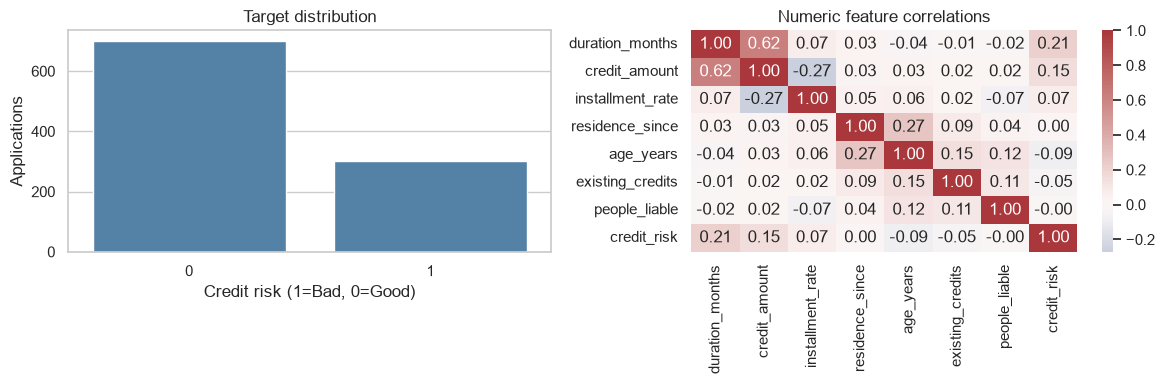

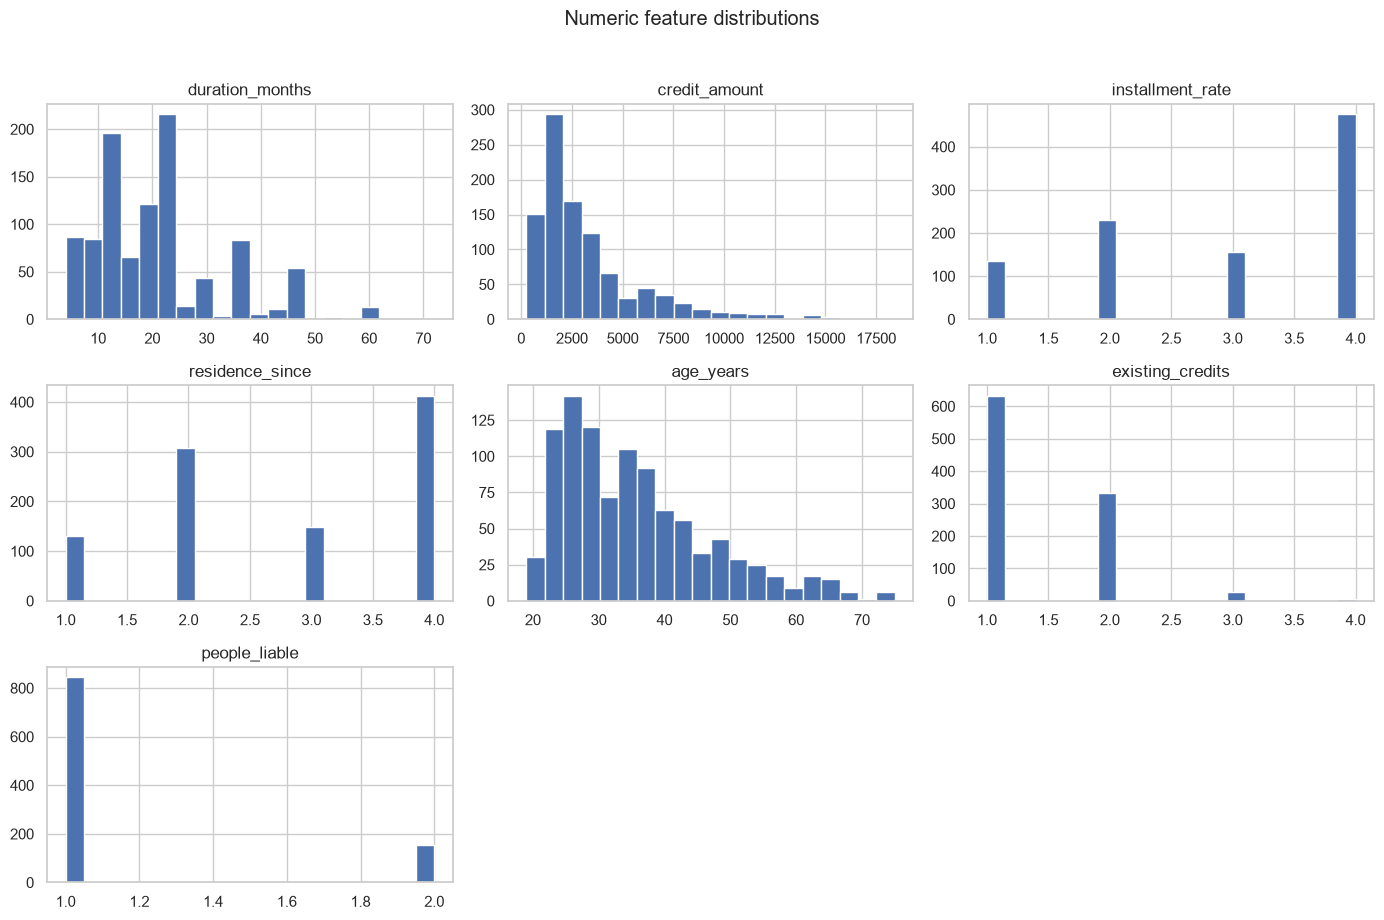

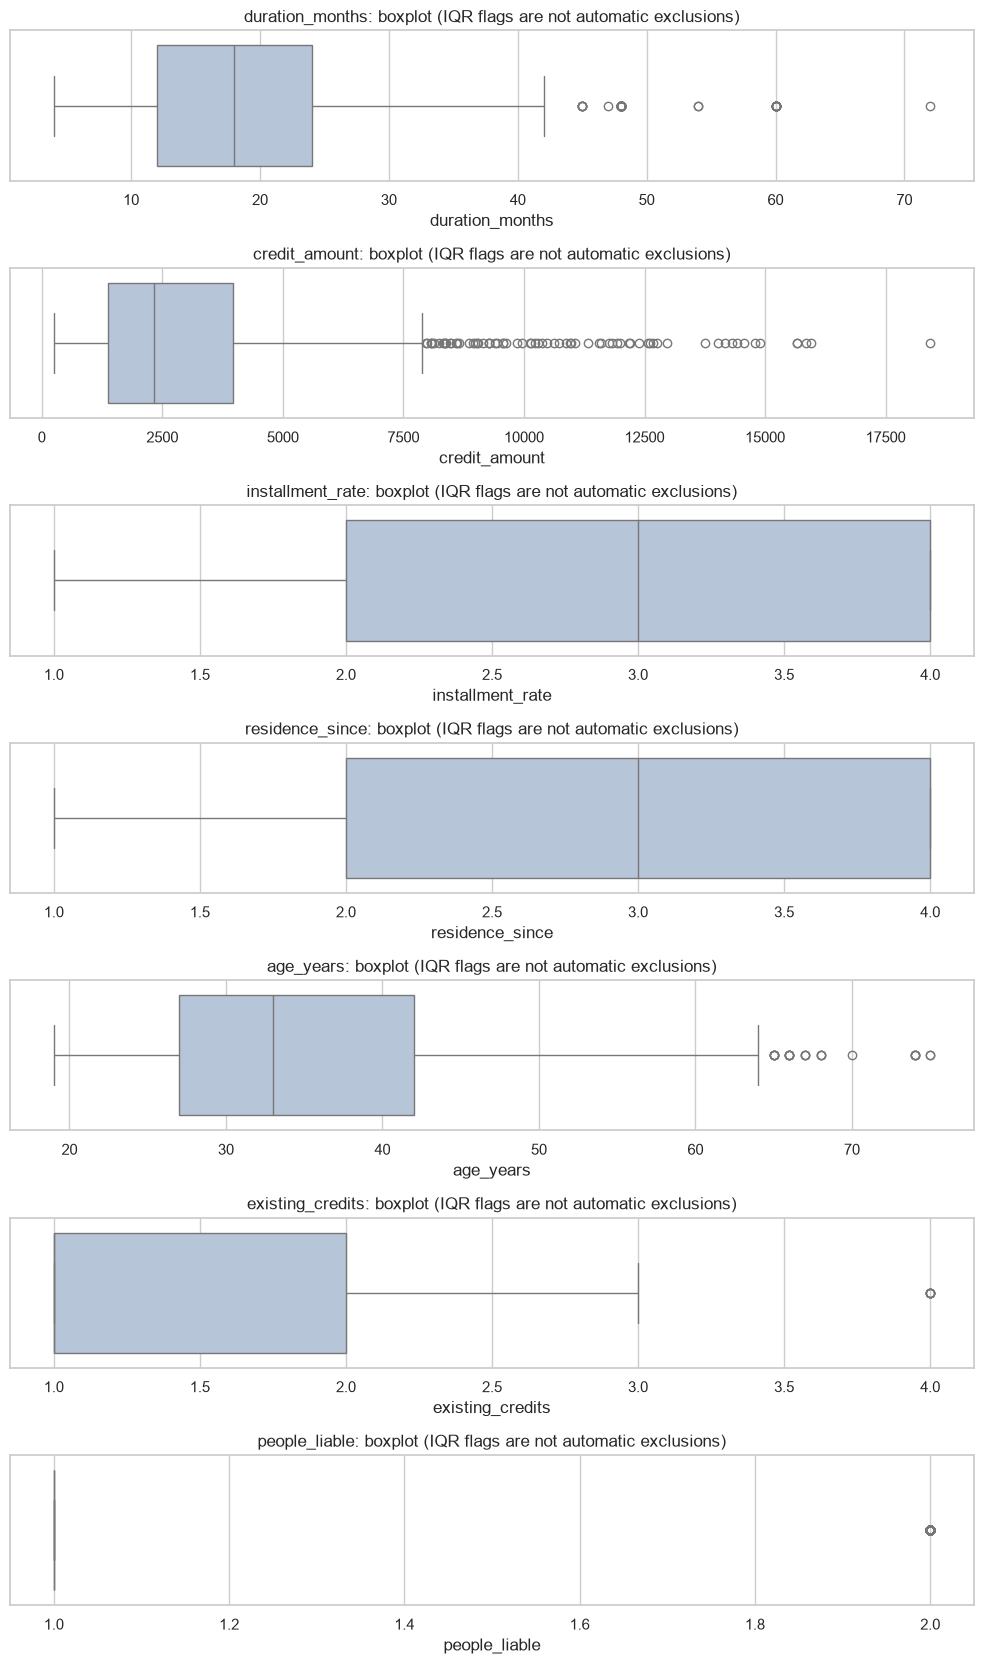

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=clean, x="credit_risk", ax=axes[0], color="steelblue")
axes[0].set(title="Target distribution", xlabel="Credit risk (1=Bad, 0=Good)", ylabel="Applications")
sns.heatmap(clean[numeric_columns + ["credit_risk"]].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[1])
axes[1].set_title("Numeric feature correlations")
plt.tight_layout()
show_and_save("figure_11_1")

clean[numeric_columns].hist(bins=20, figsize=(14, 9), edgecolor="white")
plt.suptitle("Numeric feature distributions", y=1.02)
plt.tight_layout()
show_and_save("figure_11_2")

fig, axes = plt.subplots(len(numeric_columns), 1, figsize=(10, 2.4 * len(numeric_columns)))
for ax, column in zip(axes, numeric_columns):
    sns.boxplot(data=clean, x=column, ax=ax, color="lightsteelblue")
    ax.set_title(f"{column}: boxplot (IQR flags are not automatic exclusions)")
plt.tight_layout()
show_and_save("figure_11_3")

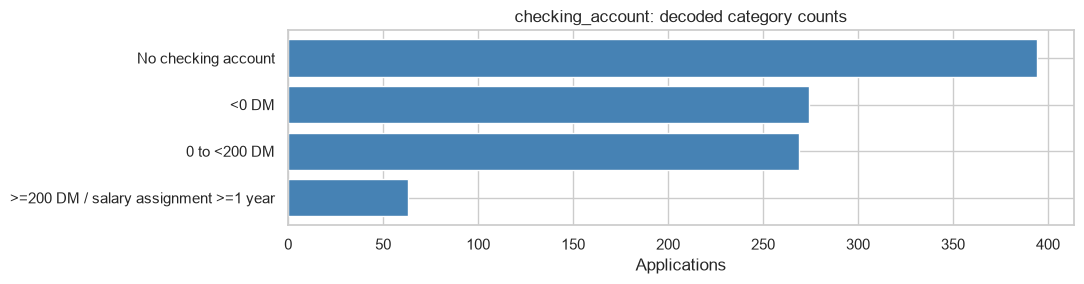

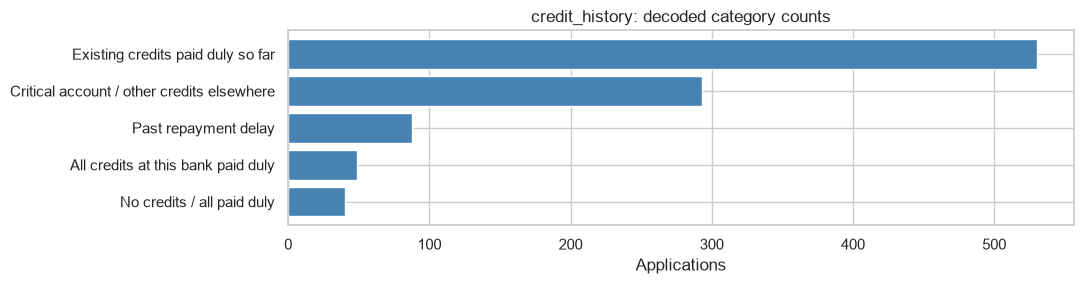

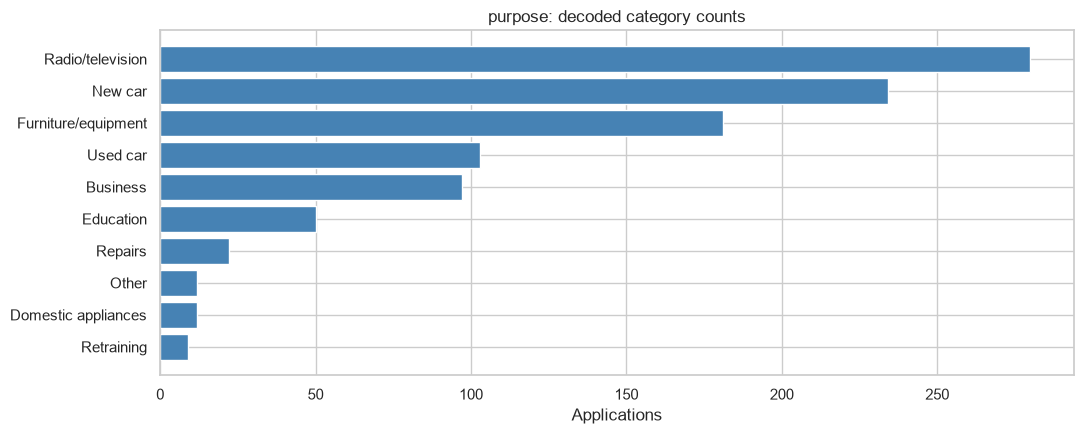

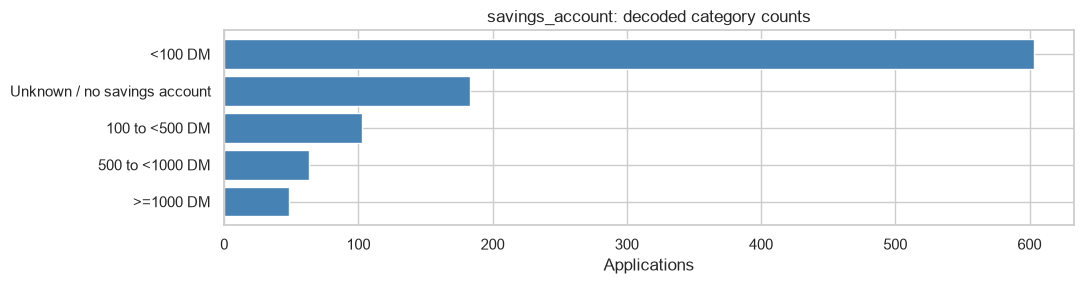

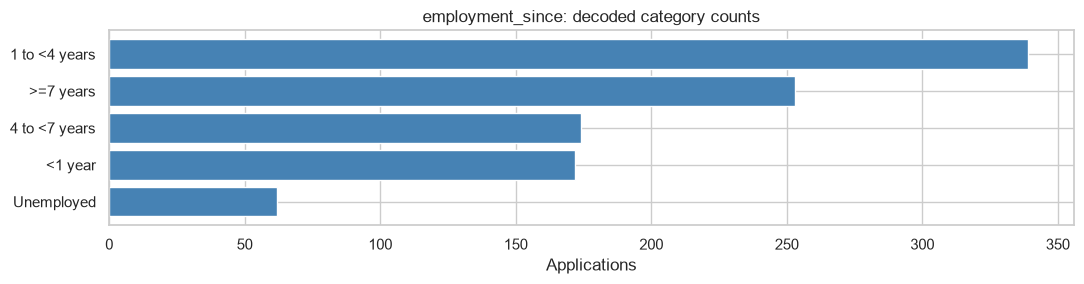

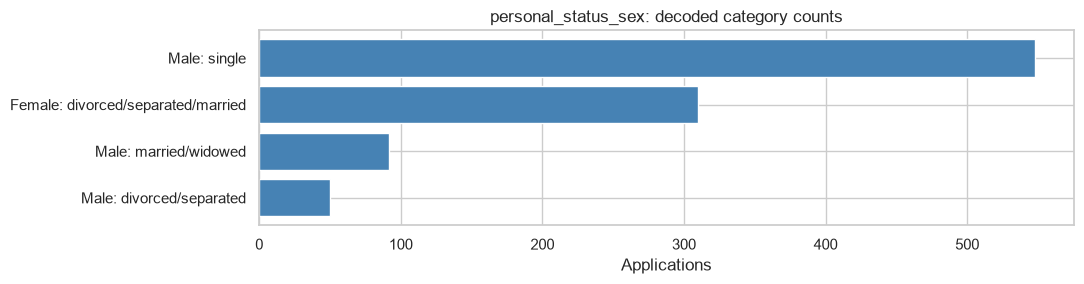

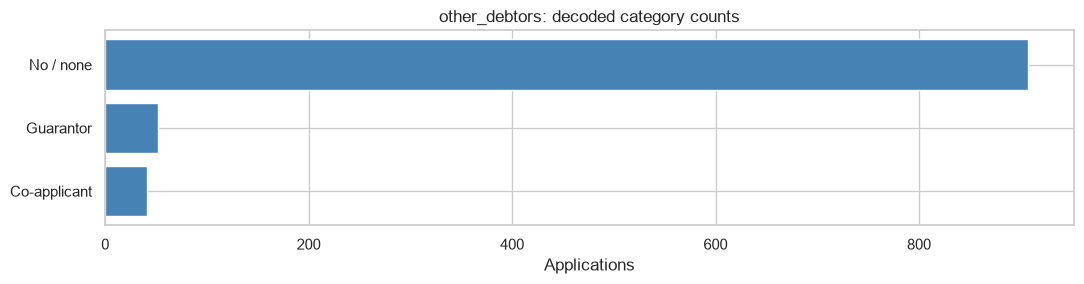

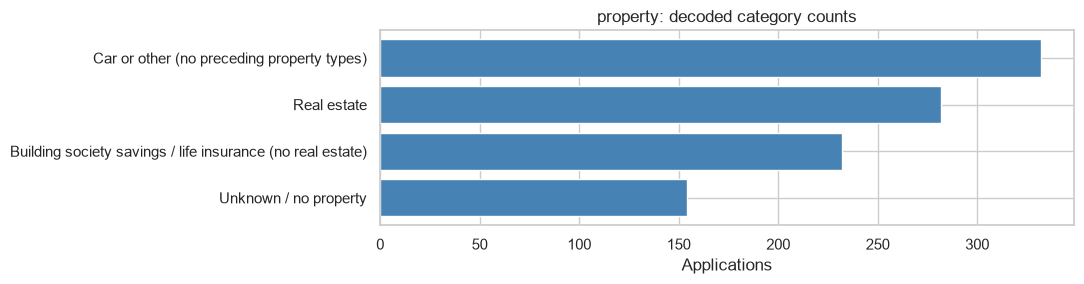

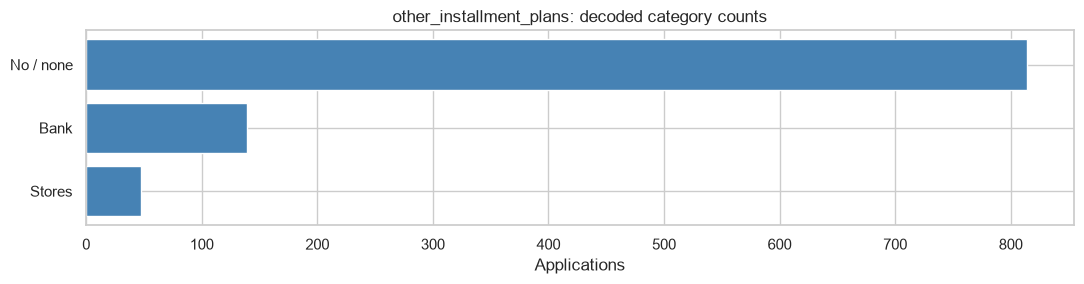

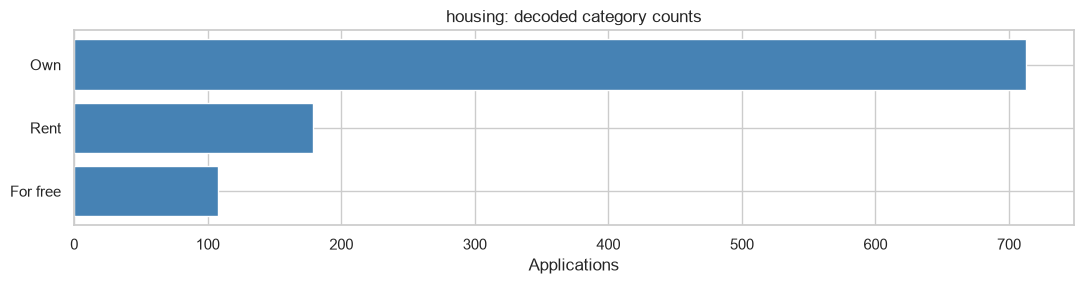

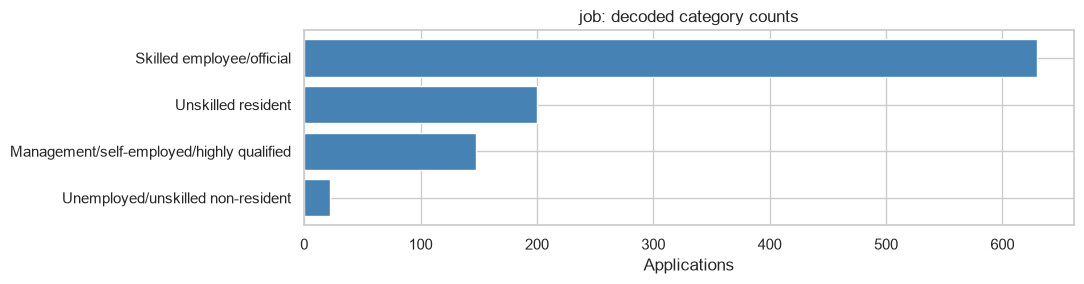

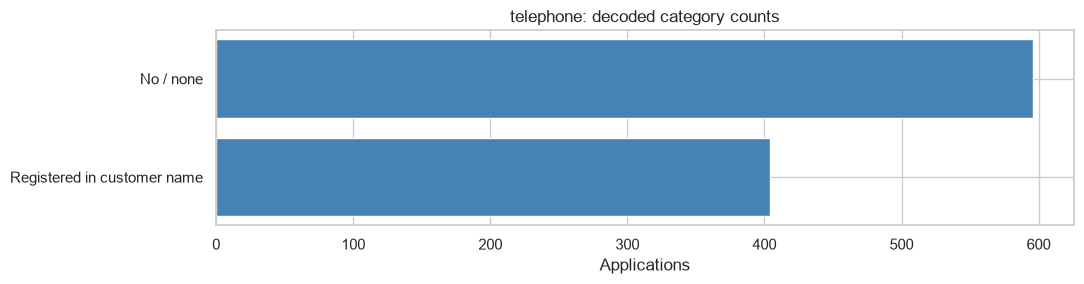

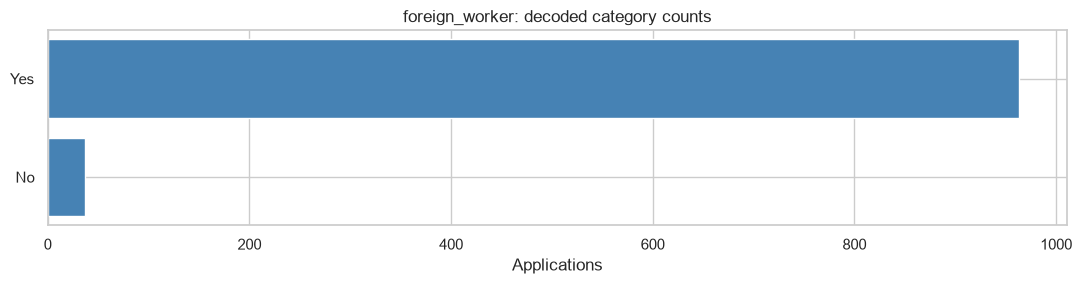

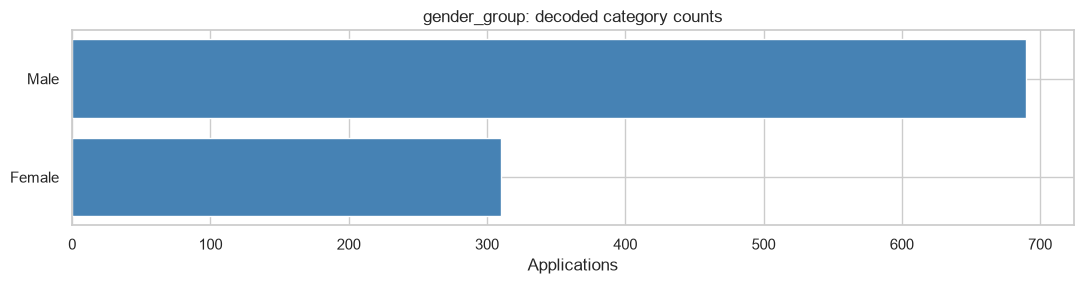

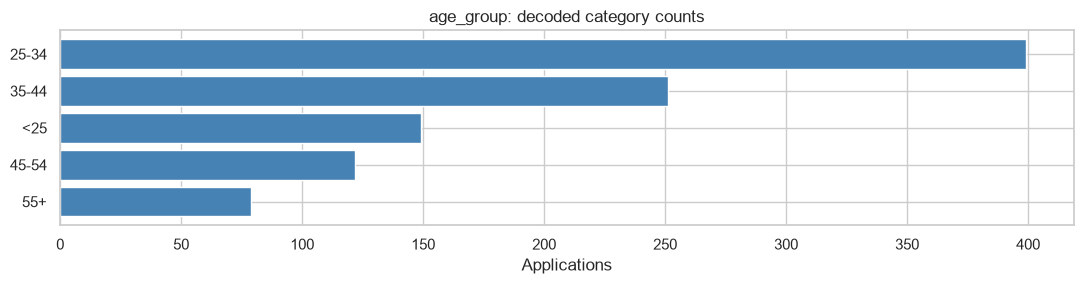

In [11]:
for column in categorical_columns + ["gender_group", "age_group"]:
    counts = clean[column].value_counts().sort_values(ascending=True)
    fig, ax = plt.subplots(figsize=(11, max(3, 0.45 * len(counts))))
    ax.barh(counts.index, counts.values, color="steelblue")
    ax.set(title=f"{column}: decoded category counts", xlabel="Applications", ylabel="")
    plt.tight_layout()
    show_and_save(f"category_{column}")


### 4. Fixed train/test split

Stratified 80/20 split, seed 4212. Preserve source row IDs for reproducible handoff.


In [12]:
train_df, test_df = train_test_split(
    clean,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=clean["original_label"].eq(1).astype(int)  # Preserve original Good=1 split ordering,
)
train_df = train_df.sort_values("original_row_index")
test_df = test_df.sort_values("original_row_index")

clean.to_csv(OUTPUT_DIR / "cleaned_german_credit.csv", index=False)
train_df.to_csv(OUTPUT_DIR / "train.csv", index=False)
test_df.to_csv(OUTPUT_DIR / "test.csv", index=False)
print(f"Train: {len(train_df)} rows; test: {len(test_df)} rows; random_state={RANDOM_STATE}")
print("Train target proportions:")
display(train_df["credit_risk"].value_counts(normalize=True).sort_index().rename("proportion").to_frame())
print("Test target proportions:")
display(test_df["credit_risk"].value_counts(normalize=True).sort_index().rename("proportion").to_frame())
print(f"Saved handoff files under: {OUTPUT_DIR.resolve()}")

Train: 800 rows; test: 200 rows; random_state=4212
Train target proportions:


,proportion
credit_risk,
0,0.7
1,0.3


Test target proportions:


,proportion
credit_risk,
0,0.7
1,0.3


Saved handoff files under: C:\Users\zheng\XN\Uni\Y4S1\DSE4212\Final Project\DSE4212-Creditscoring\outputs


## 5. Cost-sensitive baseline and fairness audit

Positive class: **Bad = 1**, Good = 0. Approval means predicted Good, not an observed lending decision.

False approval (Bad predicted Good) costs 5; false denial (Good predicted Bad) costs 1. For p = P(Bad), approval costs 5p and denial costs 1-p. Predict Bad when p >= 1/6; approve otherwise. This fixed rule assumes calibrated probabilities; the baseline is not separately calibrated. No test labels are used to select the threshold.

- Total cost = 5 x false approvals + false denials = 5 x FN + FP.
- Approval rate = predicted Good / group size.
- FPR = Good predicted Bad / actually Good (false denial).
- FNR = Bad predicted Good / actually Bad (false approval).

Compare with the standard 0.5 threshold. Small group denominators make estimates uncertain. Tune/calibrate final models within training data only.


In [13]:
sensitive_and_metadata = {
    "original_row_index", "original_label", "credit_risk", "gender_group", "age_group",
    "age_years", "personal_status_sex",
}
model_numeric = [c for c in numeric_columns if c not in sensitive_and_metadata]
model_categorical = [c for c in categorical_columns if c not in sensitive_and_metadata]
model_features = model_numeric + model_categorical

preprocessor = ColumnTransformer(transformers=[
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), model_numeric),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), model_categorical),
])
baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
baseline.fit(train_df[model_features], train_df["credit_risk"])
y_true = test_df["credit_risk"].to_numpy()
FALSE_APPROVAL_COST = 5
FALSE_DENIAL_COST = 1
BAD_RISK_THRESHOLD = FALSE_DENIAL_COST / (FALSE_APPROVAL_COST + FALSE_DENIAL_COST)
probability_bad = baseline.predict_proba(test_df[model_features])[:, list(baseline.classes_).index(1)]
y_pred = (probability_bad >= BAD_RISK_THRESHOLD).astype(int)
y_pred_standard = (probability_bad >= 0.5).astype(int)

def decision_cost_summary(truth, prediction, policy, threshold):
    truth, prediction = np.asarray(truth), np.asarray(prediction)
    fp = int(((truth == 0) & (prediction == 1)).sum())
    fn = int(((truth == 1) & (prediction == 0)).sum())
    total = FALSE_APPROVAL_COST * fn + FALSE_DENIAL_COST * fp
    return {"policy": policy, "threshold_bad": threshold,
            "false_approvals": fn, "false_denials": fp,
            "total_cost": total, "mean_cost": total / len(truth),
            "accuracy": float((truth == prediction).mean()),
            "approval_rate": float((prediction == 0).mean())}

cost_comparison = pd.DataFrame([
    decision_cost_summary(y_true, y_pred_standard, "Standard threshold", 0.5),
    decision_cost_summary(y_true, y_pred, "Cost-matrix threshold", BAD_RISK_THRESHOLD),
])
cost_comparison.to_csv(OUTPUT_DIR / "baseline_cost_comparison.csv", index=False)
display(cost_comparison.round(4))
print(f"Predict Bad when P(Bad) >= {BAD_RISK_THRESHOLD:.6f}")
print(f"Cost-sensitive baseline test accuracy: {(y_true == y_pred).mean():.3f}")
print(f"Model predictors ({len(model_features)}): {model_features}")

,policy,threshold_bad,false_approvals,false_denials,total_cost,mean_cost,accuracy,approval_rate
0,Standard threshold,0.5000,28,16,156,0.780,0.780,0.760
1,Cost-matrix threshold,0.1667,10,61,111,0.555,0.645,0.445


Predict Bad when P(Bad) >= 0.166667
Cost-sensitive baseline test accuracy: 0.645
Model predictors (18): ['duration_months', 'credit_amount', 'installment_rate', 'residence_since', 'existing_credits', 'people_liable', 'checking_account', 'credit_history', 'purpose', 'savings_account', 'employment_since', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']


In [14]:
def group_fairness_table(frame, truth, prediction, group_column, dimension):
    audit = frame[[group_column]].copy()
    audit["actual_good"] = np.asarray(truth) == 0
    audit["predicted_good"] = np.asarray(prediction) == 0
    rows = []
    for group, part in audit.groupby(group_column, dropna=False, observed=True):
        actual_good = part["actual_good"]
        predicted_good = part["predicted_good"]
        actual_bad = ~actual_good
        approved = predicted_good
        false_approval_count = int((actual_bad & approved).sum())
        false_denial_count = int((actual_good & ~predicted_good).sum())
        bad_count = int(actual_bad.sum())
        good_count = int(actual_good.sum())
        rows.append({
            "dimension": dimension,
            "group": str(group),
            "n": int(len(part)),
            "actual_good_n": good_count,
            "actual_bad_n": bad_count,
            "predicted_approved_n": int(approved.sum()),
            "approval_rate": float(approved.mean()),
            "false_approval_n": false_approval_count,
            "false_approval_denominator_bad": bad_count,
            "false_negative_rate": false_approval_count / bad_count if bad_count else np.nan,
            "total_cost": FALSE_APPROVAL_COST * false_approval_count + FALSE_DENIAL_COST * false_denial_count,
            "mean_cost": (FALSE_APPROVAL_COST * false_approval_count + FALSE_DENIAL_COST * false_denial_count) / len(part),
            "false_denial_n": false_denial_count,
            "false_denial_denominator_good": good_count,
            "false_positive_rate": false_denial_count / good_count if good_count else np.nan,
        })
    return pd.DataFrame(rows)

gender_fairness = group_fairness_table(test_df, y_true, y_pred, "gender_group", "gender")
age_fairness = group_fairness_table(test_df, y_true, y_pred, "age_group", "age")
fairness = pd.concat([gender_fairness, age_fairness], ignore_index=True)
age_order = {v: i for i, v in enumerate(["<25", "25-34", "35-44", "45-54", "55+"])}
fairness["_order"] = fairness["group"].map(age_order).fillna(-1)
fairness = fairness.sort_values(["dimension", "_order", "group"]).drop(columns="_order").reset_index(drop=True)
fairness.to_csv(OUTPUT_DIR / "fairness_by_group.csv", index=False)
display(fairness.round(4))


for dimension, result in fairness.groupby("dimension"):
    print(f"{dimension.title()} max-minus-min rate gaps (descriptive only):")
    display((result[["approval_rate", "false_positive_rate", "false_negative_rate"]].max()
             - result[["approval_rate", "false_positive_rate", "false_negative_rate"]].min())
            .rename("gap").to_frame())

,dimension,group,n,actual_good_n,actual_bad_n,predicted_approved_n,approval_rate,false_approval_n,false_approval_denominator_bad,false_negative_rate,total_cost,mean_cost,false_denial_n,false_denial_denominator_good,false_positive_rate
0,age,<25,30,15,15,5,0.1667,1,15,0.0667,16,0.5333,11,15,0.7333
1,age,25-34,78,54,24,33,0.4231,3,24,0.1250,39,0.5000,24,54,0.4444
2,age,35-44,47,36,11,26,0.5532,4,11,0.3636,34,0.7234,14,36,0.3889
3,age,45-54,28,20,8,16,0.5714,2,8,0.2500,16,0.5714,6,20,0.3000
4,age,55+,17,15,2,9,0.5294,0,2,0.0000,6,0.3529,6,15,0.4000
5,gender,Female,57,37,20,22,0.3860,2,20,0.1000,27,0.4737,17,37,0.4595
6,gender,Male,143,103,40,67,0.4685,8,40,0.2000,84,0.5874,44,103,0.4272


Age max-minus-min rate gaps (descriptive only):


,gap
approval_rate,0.404762
false_positive_rate,0.433333
false_negative_rate,0.363636


Gender max-minus-min rate gaps (descriptive only):


,gap
approval_rate,0.082567
false_positive_rate,0.032275
false_negative_rate,0.100000


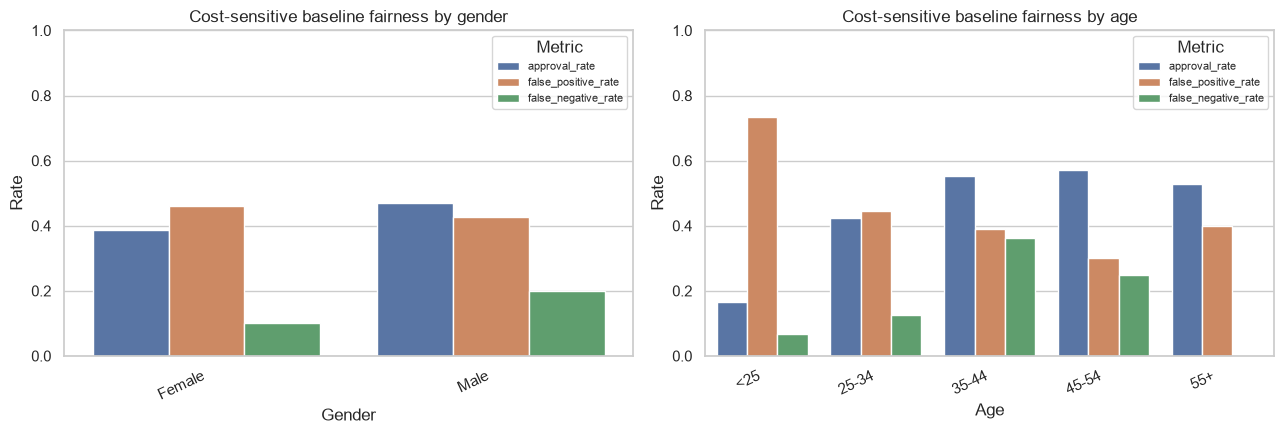

Fairness results saved to: C:\Users\zheng\XN\Uni\Y4S1\DSE4212\Final Project\DSE4212-Creditscoring\outputs\fairness_by_group.csv


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, dimension in zip(axes, ["gender", "age"]):
    subset = fairness[fairness["dimension"] == dimension].melt(
        id_vars=["group", "n"],
        value_vars=["approval_rate", "false_positive_rate", "false_negative_rate"],
        var_name="metric", value_name="rate",
    )
    sns.barplot(data=subset, x="group", y="rate", hue="metric", ax=ax)
    ax.set(title=f"Cost-sensitive baseline fairness by {dimension}", xlabel=dimension.title(), ylabel="Rate")
    ax.set_ylim(0, 1)
    ax.legend(title="Metric", fontsize=8)
    for tick in ax.get_xticklabels():
        tick.set_rotation(25)
        tick.set_ha("right")
plt.tight_layout()
show_and_save("fairness_by_group")
print(f"Fairness results saved to: {(OUTPUT_DIR / 'fairness_by_group.csv').resolve()}")

In [16]:
# Export predictions so teammates can independently reproduce the fairness table.
prediction_audit = test_df[["original_row_index", "gender_group", "age_group", "credit_risk"]].copy()
prediction_audit["probability_bad"] = probability_bad
prediction_audit["predicted_bad"] = y_pred
prediction_audit["predicted_bad_standard"] = y_pred_standard
prediction_audit["decision_cost"] = np.where((y_true == 1) & (y_pred == 0), FALSE_APPROVAL_COST,
                                           np.where((y_true == 0) & (y_pred == 1), FALSE_DENIAL_COST, 0))
assert prediction_audit["decision_cost"].sum() == cost_comparison.iloc[1]["total_cost"]
prediction_audit.to_csv(OUTPUT_DIR / "baseline_test_predictions.csv", index=False)
split_membership = pd.concat([train_df[["original_row_index"]].assign(split="train"),
                              test_df[["original_row_index"]].assign(split="test")]).sort_values("original_row_index")
split_membership.to_csv(OUTPUT_DIR / "split_membership.csv", index=False)
